# 3.1 Script Structure

In [1]:
# Import libraries
import json
import sqlite3
from contextlib import closing
from datetime import date
from pathlib import Path

import pandas as pd
import papermill as pm
from tqdm import tqdm

import scrapbook as sb
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Set up path and template
base_dir = Path.cwd()
template = base_dir / "02_stock_report_template.ipynb"
db_path = base_dir / "data.db"

# Check that data and stock template (notebook 2) are found
if not db_path.is_file():
    raise FileNotFoundError(f"Database not found at {db_path}")
if not template.is_file():
    raise FileNotFoundError(f"Template notebook not found at {template}")

In [3]:
# Define function to find the last six months
def six_complete_months(latest_date: str) -> tuple[str, str]:
    """Determine the date range: last 6 complete months in the database"""
    latest = pd.Timestamp(latest_date)
    # Check that the latest value isn't na
    if pd.isna(latest):
        raise ValueError("Cannot choose a window from an empty date range.")
    month_start = latest.to_period("M").start_time
    # Start six months eariler
    start = month_start - pd.DateOffset(months=6)
    # End one day before the 'month_start'
    end = month_start - pd.Timedelta(days=1)
    return start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")

# Check the example in the instructions just to make sure that the function is written and 
# excecutes correctly
assert six_complete_months("2024-12-06") == ("2024-06-01", "2024-11-30")

In [4]:
# Load data from ohlc_hw_cleaned
ro_uri = db_path.resolve().as_uri() + "?mode=ro"
with closing(sqlite3.connect(ro_uri, uri=True)) as conn:
    tickers = pd.read_sql_query(
        "SELECT DISTINCT ticker FROM ohlc_hw_cleaned WHERE ticker IS NOT NULL ORDER BY ticker",
        conn,
    )["ticker"].tolist()
    latest_date = pd.read_sql_query(
        "SELECT MAX(ts) AS latest FROM ohlc_hw_cleaned",
        conn,
    )["latest"].iloc[0]

# Compute the start and end date using latest data and six_complete_months function
start_date, end_date = six_complete_months(latest_date)

In [5]:
# Create output directory: reports/{YYYY-MM-DD}/, where the date is the run date
run_date_str = date.today().strftime("%Y-%m-%d")
run_dir = base_dir / "reports" / run_date_str
run_dir.mkdir(parents=True, exist_ok=True)


# Print the tickers again to be sure
#print(f"Available tickers ({len(tickers)}): {tickers}")
# Print latest date, 6 month window, and where the directory is
print(f"Database latest observation: {latest_date}")
print(f"Historical 6-month window:   {start_date} to {end_date}")
#print(f"Output directory created:    {run_dir}")

Database latest observation: 2024-12-06 00:00:00
Historical 6-month window:   2024-06-01 to 2024-11-30


In [6]:
# Define a function that runs a report on a ticker/stock
def run_report(template_path: Path, ticker: str, start: str, end: str, folder: Path,) -> Path:
    """Apply the 02 notebook template to a ticker and save the output to reports/{date}/{ticker}_report.ipynb."""
    folder.mkdir(parents=True, exist_ok=True)
    output = folder / f"{ticker}_report.ipynb"
    pm.execute_notebook(
        str(template_path),
        str(output),
        parameters={
            "ticker": ticker,
            "start_date": start,
            "end_date": end,
        },
        cwd=str(template_path.parent),
        progress_bar=False,
    )
    return output

# 3.2 Progress Tracking

In [7]:
successful_paths = []
failures = []

# Implement the progress tracker and run the reports for each ticker
for ticker in tqdm(tickers, desc="Generating reports"):
    try:
        out_path = run_report(template, ticker, start_date, end_date, run_dir)
        successful_paths.append(out_path)
    # if not successful
    except Exception as exc:
        # Log the error and move on
        err_msg = str(exc).splitlines()[1] if str(exc) else "Unknown error"
        failures.append({"ticker": ticker, "error": err_msg})
        print(f"\n[WARNING] Failed to generate report for {ticker}: {err_msg}")

Generating reports: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [01:12<00:00,  2.40s/it]


In [8]:
# Save failed tickers to failed_stocks.txt and failed_stocks.json
(run_dir / "failed_stocks.txt").write_text("".join(item["ticker"] + "\n" for item in failures))
# Save Complete List of reports and failures
(run_dir / "manifest.json").write_text(
    json.dumps(
        {
            "run_date": run_date_str,
            "start_date": start_date,
            "end_date": end_date,
            "reports": [path.name for path in successful_paths],
            "failures": failures,
        },
        indent=2,
    )
)

# Print success rate and message for all failures
total_tickers = len(tickers)
num_success = len(successful_paths)

print(f"Successfully generated {num_success}/{total_tickers} reports")

if num_success == 0:
    print("All reports failed. No summary statistics to compute.")
else:
    print(f"Reports successfully saved in: {run_dir}")
    if failures:
        print(f"Failed tickers logged to: {run_dir / 'failed_stocks.txt'}")


Successfully generated 30/30 reports
Reports successfully saved in: /Users/valeriemacisaac/ucb_mfe/git/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/valerie_macisaac/reports/2026-10-28


# 3.3 Summary Dashboard

TOP 10 STOCKS BY SHARPE RATIO:


,ticker,sharpe_ratio,total_return,avg_volatility
24,SHW,3.608183,0.288435,0.168133
13,IBM,3.149172,0.398844,0.205483
11,HD,3.055127,0.272889,0.205666
29,WMT,3.037790,0.238915,0.178377
17,MCD,2.997731,0.225712,0.170758
7,CSCO,2.574669,0.236166,0.198214
18,MMM,2.263478,0.361887,0.310889
6,CRM,2.149827,0.250333,0.268323
25,TRV,2.136434,0.242209,0.213385
14,JNJ,2.080752,0.126100,0.142052


BOTTOM 10 STOCKS BY SHARPE RATIO:


,ticker,sharpe_ratio,total_return,avg_volatility
2,AMZN,0.945083,0.165695,0.305773
22,NVDA,0.935793,0.200209,0.508258
27,V,0.854505,0.077009,0.205872
1,AMGN,0.638035,0.058998,0.207925
16,KO,0.446993,0.041105,0.135382
8,CVX,0.398803,0.050538,0.202488
20,MSFT,0.081552,0.013034,0.173459
21,NKE,-0.914788,-0.161818,0.360802
4,BA,-1.516548,-0.158531,0.316378
19,MRK,-1.942186,-0.198486,0.231501


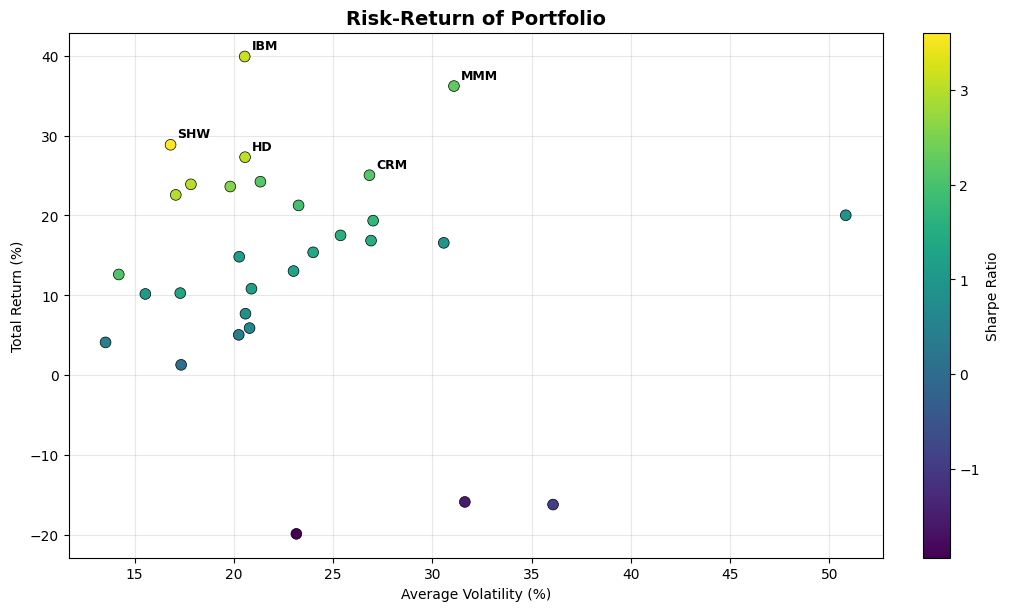

In [9]:
# Collect using Scrapbook to make summary 
def to_float(scrap_dict, key):
    """Function to convert the scrapbook data to floats"""
    if key not in scrap_dict or scrap_dict[key].data is None:
        return np.nan
    val = scrap_dict[key].data
    if isinstance(val, (int, float, np.number)):
        return float(val)
    val_str = str(val).strip()
    if "nan" in val_str.lower():
        return np.nan
    try:
        return float(val_str)
    except ValueError:
        return np.nan

# collect the data in summary_data
summary_data = []

for report_path in successful_paths:
    try:
        # Open each notebook via scrapbook
        nb = sb.read_notebook(str(report_path))
        scraps = nb.scraps

        # Extract the glued statistics from 02_stock_report_template.ipynb
        summary_data.append({
            "ticker": str(scraps["ticker"].data) if "ticker" in scraps else report_path.stem.split("_")[0],
            "avg_daily_return": to_float(scraps, "avg_daily_return"),
            "avg_volatility": to_float(scraps, "avg_volatility"),
            "max_drawdown": to_float(scraps, "max_drawdown"),
            "sharpe_ratio": to_float(scraps, "sharpe_ratio"),
            "total_return": to_float(scraps, "total_return"),
            "report_path": str(report_path)
        })
    except Exception as e:
        print(f"Could not read scraps from {report_path.name}: {e}")


# Build portfolio summary DataFrame
summary_df = pd.DataFrame(summary_data)

if not summary_df.empty:
    # Sort summary_df by Sharpe ratio (descending)
    summary_df.sort_values(by="sharpe_ratio", ascending=False, inplace=True)

    # Exclude undefined (NaN or infinite) Sharpe values from rankings 
    # Note: this is explicitly because I previously had an error where some sharpes were coming 
    # back as nan. 
    valid_sharpe_df = summary_df[
        summary_df["sharpe_ratio"].notna() & 
        np.isfinite(summary_df["sharpe_ratio"])
    ].copy()

    print("=" * 60)
    print("TOP 10 STOCKS BY SHARPE RATIO:")
    print("=" * 60)
    display(valid_sharpe_df.head(10)[["ticker", "sharpe_ratio", "total_return", "avg_volatility"]])

    print("=" * 60)
    print("BOTTOM 10 STOCKS BY SHARPE RATIO:")
    print("=" * 60)
    display(valid_sharpe_df.tail(10)[["ticker", "sharpe_ratio", "total_return", "avg_volatility"]])

    # Save summary to reports/{date}/portfolio_summary.csv
    csv_output_path = run_dir / "portfolio_summary.csv"
    summary_df.to_csv(csv_output_path, index=False)

    # Create scatterplot of avg volatility vs total return
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    x = valid_sharpe_df["avg_volatility"] * 100
    y = valid_sharpe_df["total_return"] * 100
    c = valid_sharpe_df["sharpe_ratio"] # to color by

    sc = ax.scatter(x, y, c=c, cmap="viridis", s=60, edgecolor="k", linewidth=0.5, zorder=3)
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label("Sharpe Ratio")

    # Annotate top 5 stocks by total return
    top_5_return = valid_sharpe_df.nlargest(5, "total_return")
    for _, row in top_5_return.iterrows():
        ax.annotate(
            row["ticker"],
            (row["avg_volatility"] * 100, row["total_return"] * 100),
            xytext=(5, 5),
            textcoords="offset points",
            fontweight="bold",
            fontsize=9
        )

    ax.set_title("Risk-Return of Portfolio", fontsize=14, fontweight="bold")
    ax.set_xlabel("Average Volatility (%)")
    ax.set_ylabel("Total Return (%)")
    ax.grid(True, alpha=0.3, zorder=1)

    # Save scatter plot
    plot_output_path = run_dir / "risk_return.png"
    plt.savefig(plot_output_path, dpi=300)
    plt.show()
    
else:
    print("Summary_df was empty.")